In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
from IPython.display import display

df = pd.read_csv("/Groceries_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (38765, 3)

First 5 rows:


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk



Column names:
['Member_number', 'Date', 'itemDescription']


In [3]:

import os

print("Current folder:", os.getcwd())
print("\nCSV files found:")

for root, dirs, files in os.walk("/"):
    dirs[:] = [d for d in dirs if d not in [
        "proc", "sys", "dev", "usr", "lib", "lib64"
    ]]
    for file in files:
        if file.lower() == "groceries_dataset.csv":
            print(os.path.join(root, file))


Current folder: /content

CSV files found:
/Groceries_dataset.csv


Total transactions (customer-date combinations): 14963

Top 10 most frequently purchased products:


,Product,Count
0,whole milk,2502
1,other vegetables,1898
2,rolls/buns,1716
3,soda,1514
4,yogurt,1334
5,root vegetables,1071
6,tropical fruit,1032
7,bottled water,933
8,sausage,924
9,citrus fruit,812


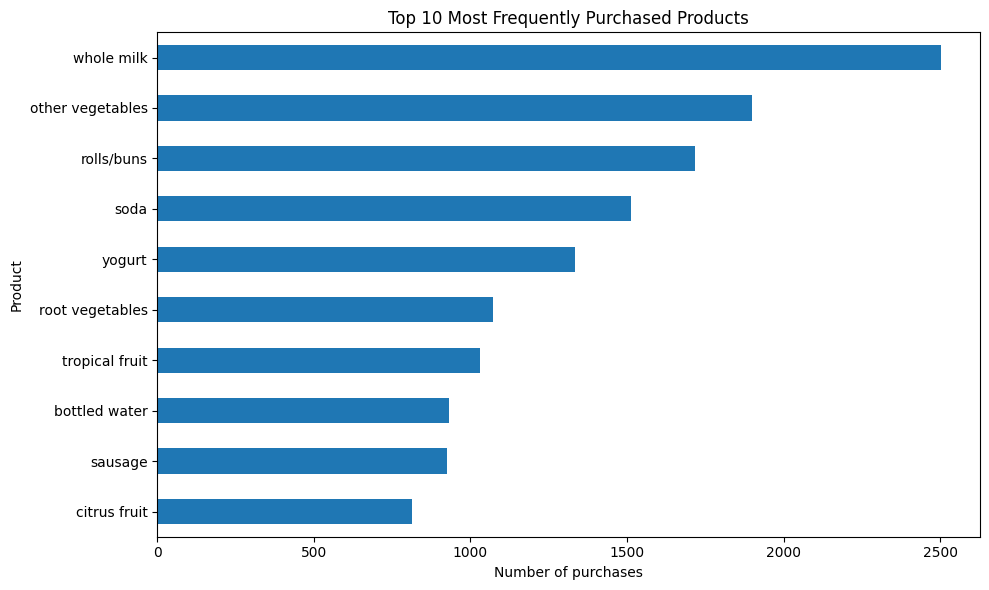

In [5]:

# 1. Clean the data
df["itemDescription"] = df["itemDescription"].astype(str).str.strip().str.lower()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.dropna(subset=["Member_number", "Date", "itemDescription"])

# 2. Count how often each product appears
product_counts = df["itemDescription"].value_counts()

print("Total transactions (customer-date combinations):",
      df.groupby(["Member_number", "Date"]).ngroups)

print("\nTop 10 most frequently purchased products:")
display(product_counts.head(10).rename_axis("Product").reset_index(name="Count"))

# 3. Visualize top 10 products
top10 = product_counts.head(10).sort_values()

plt.figure(figsize=(10, 6))
top10.plot(kind="barh")
plt.title("Top 10 Most Frequently Purchased Products")
plt.xlabel("Number of purchases")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


Total baskets: 14963

Top 15 product pairs bought together:


,Product Pair,Times Bought Together
0,"(other vegetables, whole milk)",222
1,"(rolls/buns, whole milk)",209
2,"(soda, whole milk)",174
3,"(whole milk, yogurt)",167
4,"(other vegetables, rolls/buns)",158
5,"(other vegetables, soda)",145
6,"(sausage, whole milk)",134
7,"(tropical fruit, whole milk)",123
8,"(other vegetables, yogurt)",121
9,"(rolls/buns, soda)",121


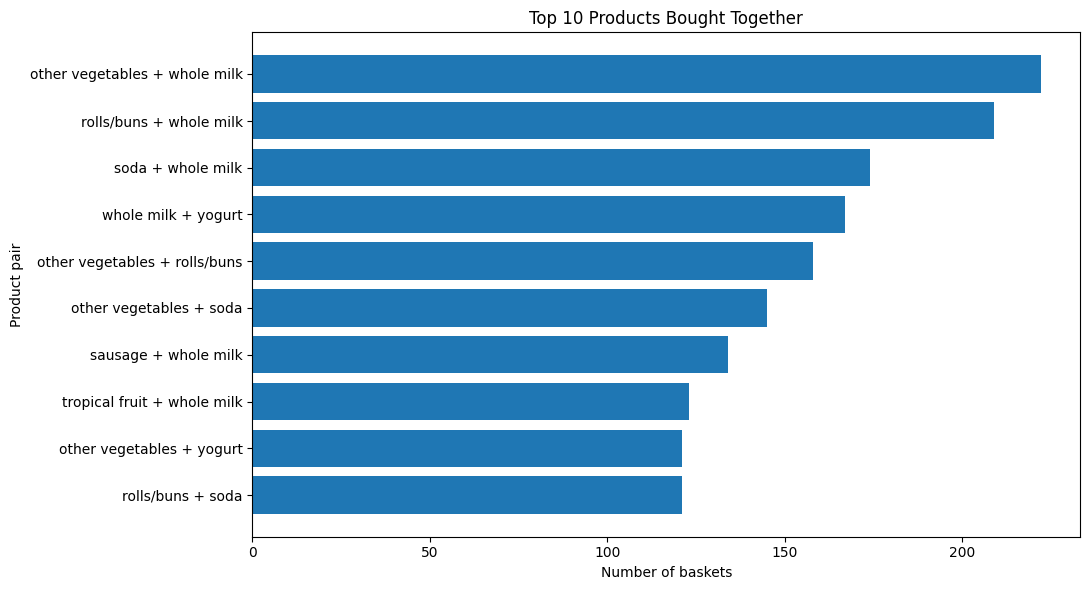

In [7]:

# Create one basket for each customer on each date
baskets = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(lambda items: sorted(set(items)))
)

print("Total baskets:", len(baskets))

# Count product pairs bought together
pair_counts = Counter()

for items in baskets:
    if len(items) >= 2:
        pair_counts.update(combinations(items, 2))

# Display the 15 most common pairs
top_pairs = pair_counts.most_common(15)

pairs_df = pd.DataFrame(
    top_pairs,
    columns=["Product Pair", "Times Bought Together"]
)

print("\nTop 15 product pairs bought together:")
display(pairs_df)

# Plot top 10 pairs
plot_df = pairs_df.head(10).copy()
plot_df["Product Pair"] = plot_df["Product Pair"].apply(
    lambda pair: " + ".join(pair)
)

plt.figure(figsize=(11, 6))
plt.barh(
    plot_df["Product Pair"][::-1],
    plot_df["Times Bought Together"][::-1]
)
plt.title("Top 10 Products Bought Together")
plt.xlabel("Number of baskets")
plt.ylabel("Product pair")
plt.tight_layout()
plt.show()


In [8]:

# Association Rule Metrics: Support, Confidence, Lift

total_baskets = len(baskets)

# Count individual product frequency in baskets
item_counts = Counter()

for items in baskets:
    item_counts.update(set(items))

rules = []

for (item_a, item_b), pair_count in pair_counts.items():
    support = pair_count / total_baskets

    confidence_a_to_b = pair_count / item_counts[item_a]
    confidence_b_to_a = pair_count / item_counts[item_b]

    support_a = item_counts[item_a] / total_baskets
    support_b = item_counts[item_b] / total_baskets

    lift_a_to_b = confidence_a_to_b / support_b
    lift_b_to_a = confidence_b_to_a / support_a

    rules.append({
        "Rule": f"{item_a} -> {item_b}",
        "Support (%)": round(support * 100, 2),
        "Confidence (%)": round(confidence_a_to_b * 100, 2),
        "Lift": round(lift_a_to_b, 3)
    })

    rules.append({
        "Rule": f"{item_b} -> {item_a}",
        "Support (%)": round(support * 100, 2),
        "Confidence (%)": round(confidence_b_to_a * 100, 2),
        "Lift": round(lift_b_to_a, 3)
    })

rules_df = pd.DataFrame(rules)

# Show the strongest rules with lift greater than 1
strong_rules = (
    rules_df[rules_df["Lift"] > 1]
    .sort_values("Lift", ascending=False)
    .drop_duplicates("Rule")
)

print("Top 15 association rules:")
display(strong_rules.head(15))


Top 15 association rules:


,Rule,Support (%),Confidence (%),Lift
4807,soups -> preservation products,0.01,2.08,311.729
4806,preservation products -> soups,0.01,100.00,311.729
12223,baby cosmetics -> artif. sweetener,0.01,33.33,171.989
12222,artif. sweetener -> baby cosmetics,0.01,3.45,171.989
5754,kitchen utensil -> pasta,0.01,100.00,123.661
5755,pasta -> kitchen utensil,0.01,0.83,123.661
11894,rubbing alcohol -> sparkling wine,0.01,20.00,65.057
11895,sparkling wine -> rubbing alcohol,0.01,2.17,65.057
10560,honey -> prosecco,0.01,7.69,60.579
10561,prosecco -> honey,0.01,5.26,60.579


In [9]:

# Filter out rare pairs to make recommendations more useful

MIN_PAIR_COUNT = 20

filtered_rules = rules_df.copy()

# Keep rules whose product pair occurs at least 20 times
filtered_rules["Pair Count"] = filtered_rules["Rule"].apply(
    lambda rule: pair_counts.get(
        tuple(sorted(rule.split(" -> "))), 0
    )
)

filtered_rules = filtered_rules[
    (filtered_rules["Pair Count"] >= MIN_PAIR_COUNT) &
    (filtered_rules["Lift"] > 1)
]

filtered_rules = filtered_rules.sort_values(
    ["Confidence (%)", "Pair Count"],
    ascending=False
)

print("Useful association rules (pair count >= 20):")
display(filtered_rules.head(15))


Useful association rules (pair count >= 20):


,Rule,Support (%),Confidence (%),Lift,Pair Count
12,semi-finished bread -> whole milk,0.17,17.61,1.115,25
2676,detergent -> whole milk,0.14,16.28,1.031,21
884,ham -> whole milk,0.27,16.02,1.014,41
3558,processed cheese -> rolls/buns,0.15,14.47,1.316,22
242,frankfurter -> other vegetables,0.51,13.63,1.116,77
3210,frozen meals -> other vegetables,0.21,12.75,1.044,32
64,red/blush wine -> rolls/buns,0.13,12.74,1.158,20
1196,meat -> other vegetables,0.21,12.70,1.040,32
530,berries -> other vegetables,0.27,12.27,1.005,40
3650,oil -> soda,0.18,12.11,1.247,27


# Market Basket Analysis — Final Report

## 1. Objective
To identify products frequently purchased together and discover associations that can help retailers improve product placement and cross-selling.

## 2. Dataset
The grocery dataset contains 38,765 purchase records with three columns: Member_number, Date, and itemDescription.

## 3. Tools Used
- Python
- Pandas and NumPy
- Matplotlib
- Google Colab

## 4. Methodology
1. Loaded and cleaned the grocery dataset.
2. Identified the most frequently purchased products.
3. Grouped purchases by customer and date to create baskets.
4. Counted product pairs purchased together.
5. Calculated Support, Confidence, and Lift.
6. Filtered product pairs occurring at least 20 times and having Lift greater than 1.

## 5. Results
Whole milk was the most frequently purchased product in the initial frequency analysis. The association-rule analysis identified several product combinations involving milk, vegetables, rolls/buns, and other grocery items.

## 6. Business Recommendations
Retailers can test product bundles, related-product promotions, and strategic product placement using frequently associated products.

## 7. Limitations
The dataset does not provide an explicit transaction ID. Grouping purchases by customer and date may combine separate shopping visits. Association rules indicate relationships, not causation.

## 8. Conclusion
The project demonstrates how market basket analysis can reveal purchasing patterns and support data-driven retail recommendations.